# Classification

**Author:** *Ali H. El-Kassas* | Senior Data Scientist


In this notebook, we will go through an example project end to end.
 
Here are the main steps you will go through:
<ol>
<li>Look at the big picture.</li>
    <ul>
    <li>Frame the Problem</li>
    <li>Select a Performance Measure</li>
    </ul>  
        
<li>Get the data.</li>
    <ul>
    <li>Take a Quick Look at the Data</li>
    <li>Create a Test Set</li>
    </ul>  
<li>Discover and visualize the data (EDA)</li> 
<li>Experimenting with Attribute Combinations (Feature Engineering)</li>
<li>Prepare the data for ML algorithms.</li>
    <ul>
    <li>Data Cleaning</li>
    <li>Handling Text and Categorical Attributes</li>
    <li>Scaling</li>
    <li>Transformation Pipelines</li>
    </ul>  
<li>Select a model and train it</li>
<li>Fine-tune your model.</li>
<li>Error Analysis</li>
<li>Present your solution.</li>
<li>Launch, monitor, and maintain your system.</li>
</ol>

In [7]:
# Load the dataset
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

In [8]:
X, y = cancer.data, cancer.target

In [9]:
import pandas as pd

X = pd.DataFrame(X, columns=cancer.feature_names)
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [13]:
import pandas as pd
pd.Series(y).value_counts(normalize=True)

1    0.627417
0    0.372583
Name: proportion, dtype: float64

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## EDA

In [10]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [11]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [16]:
X_train.corr()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
mean radius,1.000000,0.314532,0.997789,0.988886,0.186062,0.515946,0.668475,0.822570,0.163217,-0.300273,...,0.970133,0.282822,0.965936,0.943351,0.119631,0.411654,0.524067,0.735769,0.175900,0.003668
mean texture,0.314532,1.000000,0.317985,0.309964,-0.041173,0.214740,0.276222,0.266221,0.055795,-0.083201,...,0.339574,0.912994,0.340889,0.331846,0.050191,0.254213,0.283289,0.268854,0.093769,0.107275
mean perimeter,0.997789,0.317985,1.000000,0.987834,0.224332,0.567508,0.709029,0.851740,0.200440,-0.248503,...,0.969674,0.287632,0.970918,0.943063,0.151513,0.454270,0.562180,0.763547,0.202702,0.048211
mean area,0.988886,0.309964,0.987834,1.000000,0.198963,0.512307,0.678012,0.824948,0.166673,-0.267226,...,0.962829,0.271958,0.959360,0.957080,0.131227,0.392119,0.511134,0.716582,0.157698,0.005322
mean smoothness,0.186062,-0.041173,0.224332,0.198963,1.000000,0.661769,0.550461,0.572164,0.570054,0.566008,...,0.231080,0.028475,0.258177,0.228156,0.798808,0.495236,0.473253,0.518242,0.430442,0.503625
mean compactness,0.515946,0.214740,0.567508,0.512307,0.661769,1.000000,0.895918,0.842957,0.623672,0.569720,...,0.544975,0.234586,0.599982,0.522258,0.557208,0.866864,0.832984,0.821914,0.533571,0.683961
mean concavity,0.668475,0.276222,0.709029,0.678012,0.550461,0.895918,1.000000,0.922474,0.527835,0.367603,...,0.677343,0.276533,0.719681,0.664738,0.458859,0.755946,0.887825,0.858758,0.429450,0.522603
mean concave points,0.822570,0.266221,0.851740,0.824948,0.572164,0.842957,0.922474,1.000000,0.486367,0.185705,...,0.830130,0.270308,0.857224,0.810853,0.456692,0.677586,0.766984,0.910330,0.403524,0.377917
mean symmetry,0.163217,0.055795,0.200440,0.166673,0.570054,0.623672,0.527835,0.486367,1.000000,0.492612,...,0.200339,0.081881,0.236714,0.189996,0.427530,0.497527,0.466068,0.454245,0.721222,0.455720
mean fractal dimension,-0.300273,-0.083201,-0.248503,-0.267226,0.566008,0.569720,0.367603,0.185705,0.492612,1.000000,...,-0.241707,-0.053001,-0.191768,-0.216649,0.487220,0.473688,0.373834,0.190987,0.347184,0.771330


<Axes: >

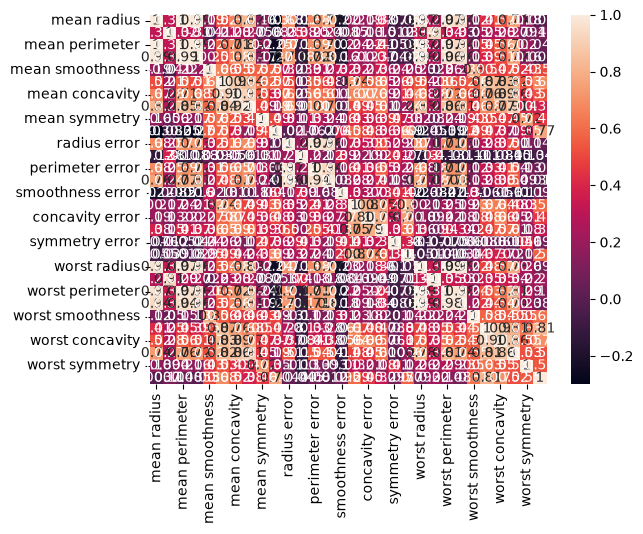

In [17]:
import seaborn as sns

sns.heatmap(X_train.corr(), annot=True)

<Axes: >

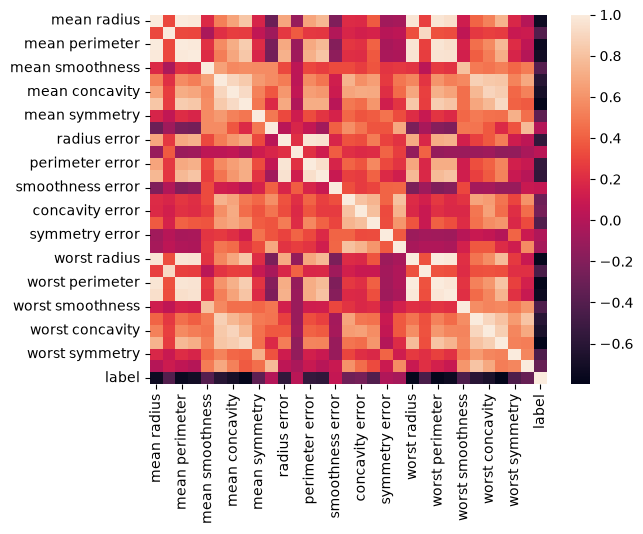

In [20]:
X_y_train = X_train.copy()
X_y_train['label'] = y_train

corr_matrix = X_y_train.corr()
sns.heatmap(corr_matrix)

In [21]:
corr_matrix['label'].abs().sort_values(ascending= False)

label                      1.000000
worst concave points       0.798176
worst perimeter            0.783376
mean concave points        0.779907
worst radius               0.776390
mean perimeter             0.745132
worst area                 0.737965
mean radius                0.732224
mean area                  0.713409
mean concavity             0.692052
worst concavity            0.668368
mean compactness           0.610722
worst compactness          0.602331
area error                 0.567197
radius error               0.565074
perimeter error            0.551905
worst texture              0.450765
worst symmetry             0.430422
worst smoothness           0.429227
concave points error       0.418560
mean texture               0.409384
mean smoothness            0.392200
mean symmetry              0.358370
worst fractal dimension    0.327308
compactness error          0.291239
concavity error            0.252785
smoothness error           0.070507
fractal dimension error    0

<Axes: >

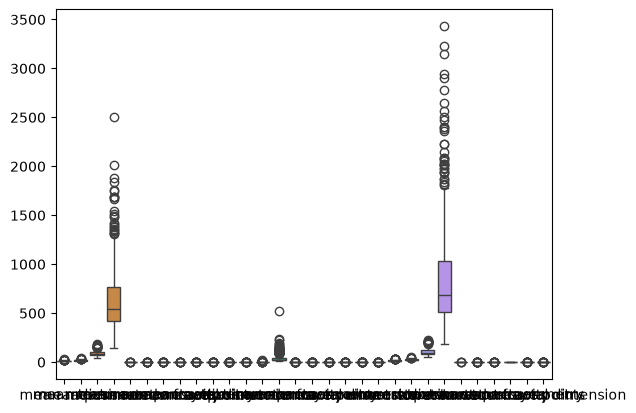

In [22]:
sns.boxplot(X_train)

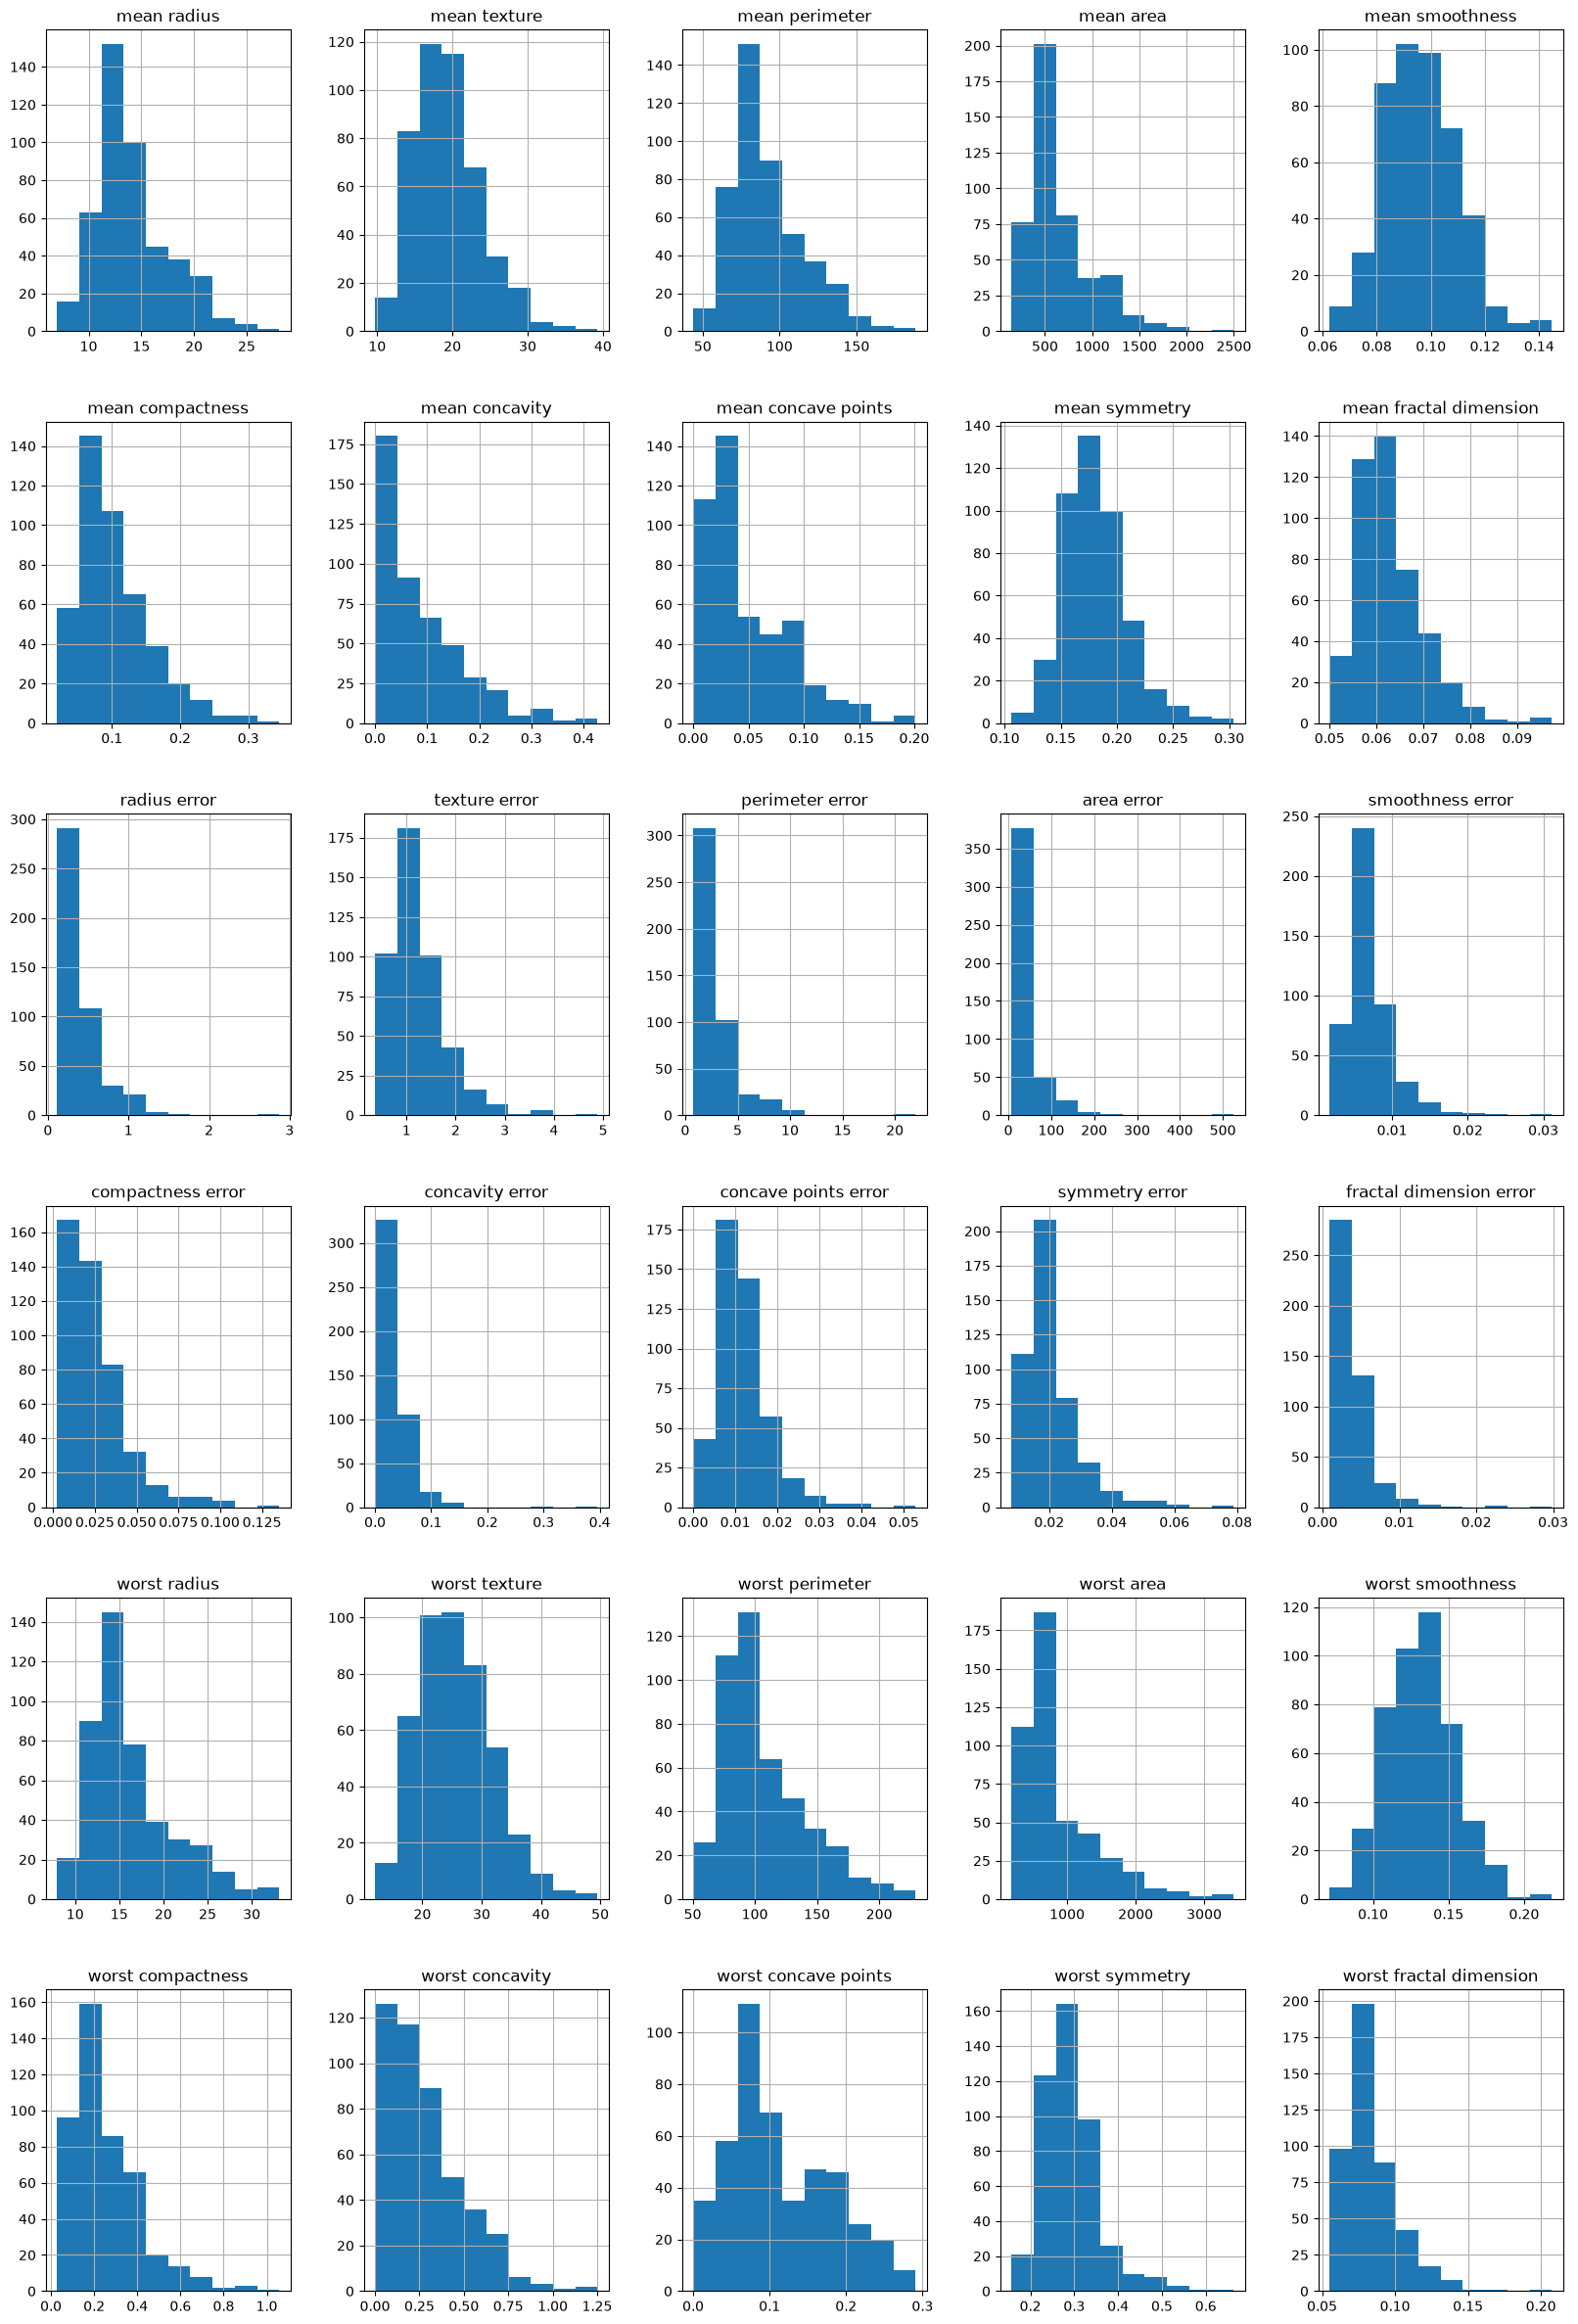

In [24]:
X_train.hist(figsize=(20,30));

## Model

In [ ]:
# import the model 
from sklearn.tree import DecisionTreeClassifier

# Step 2. initthe model 
model = DecisionTreeClassifier()

# train the model
model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

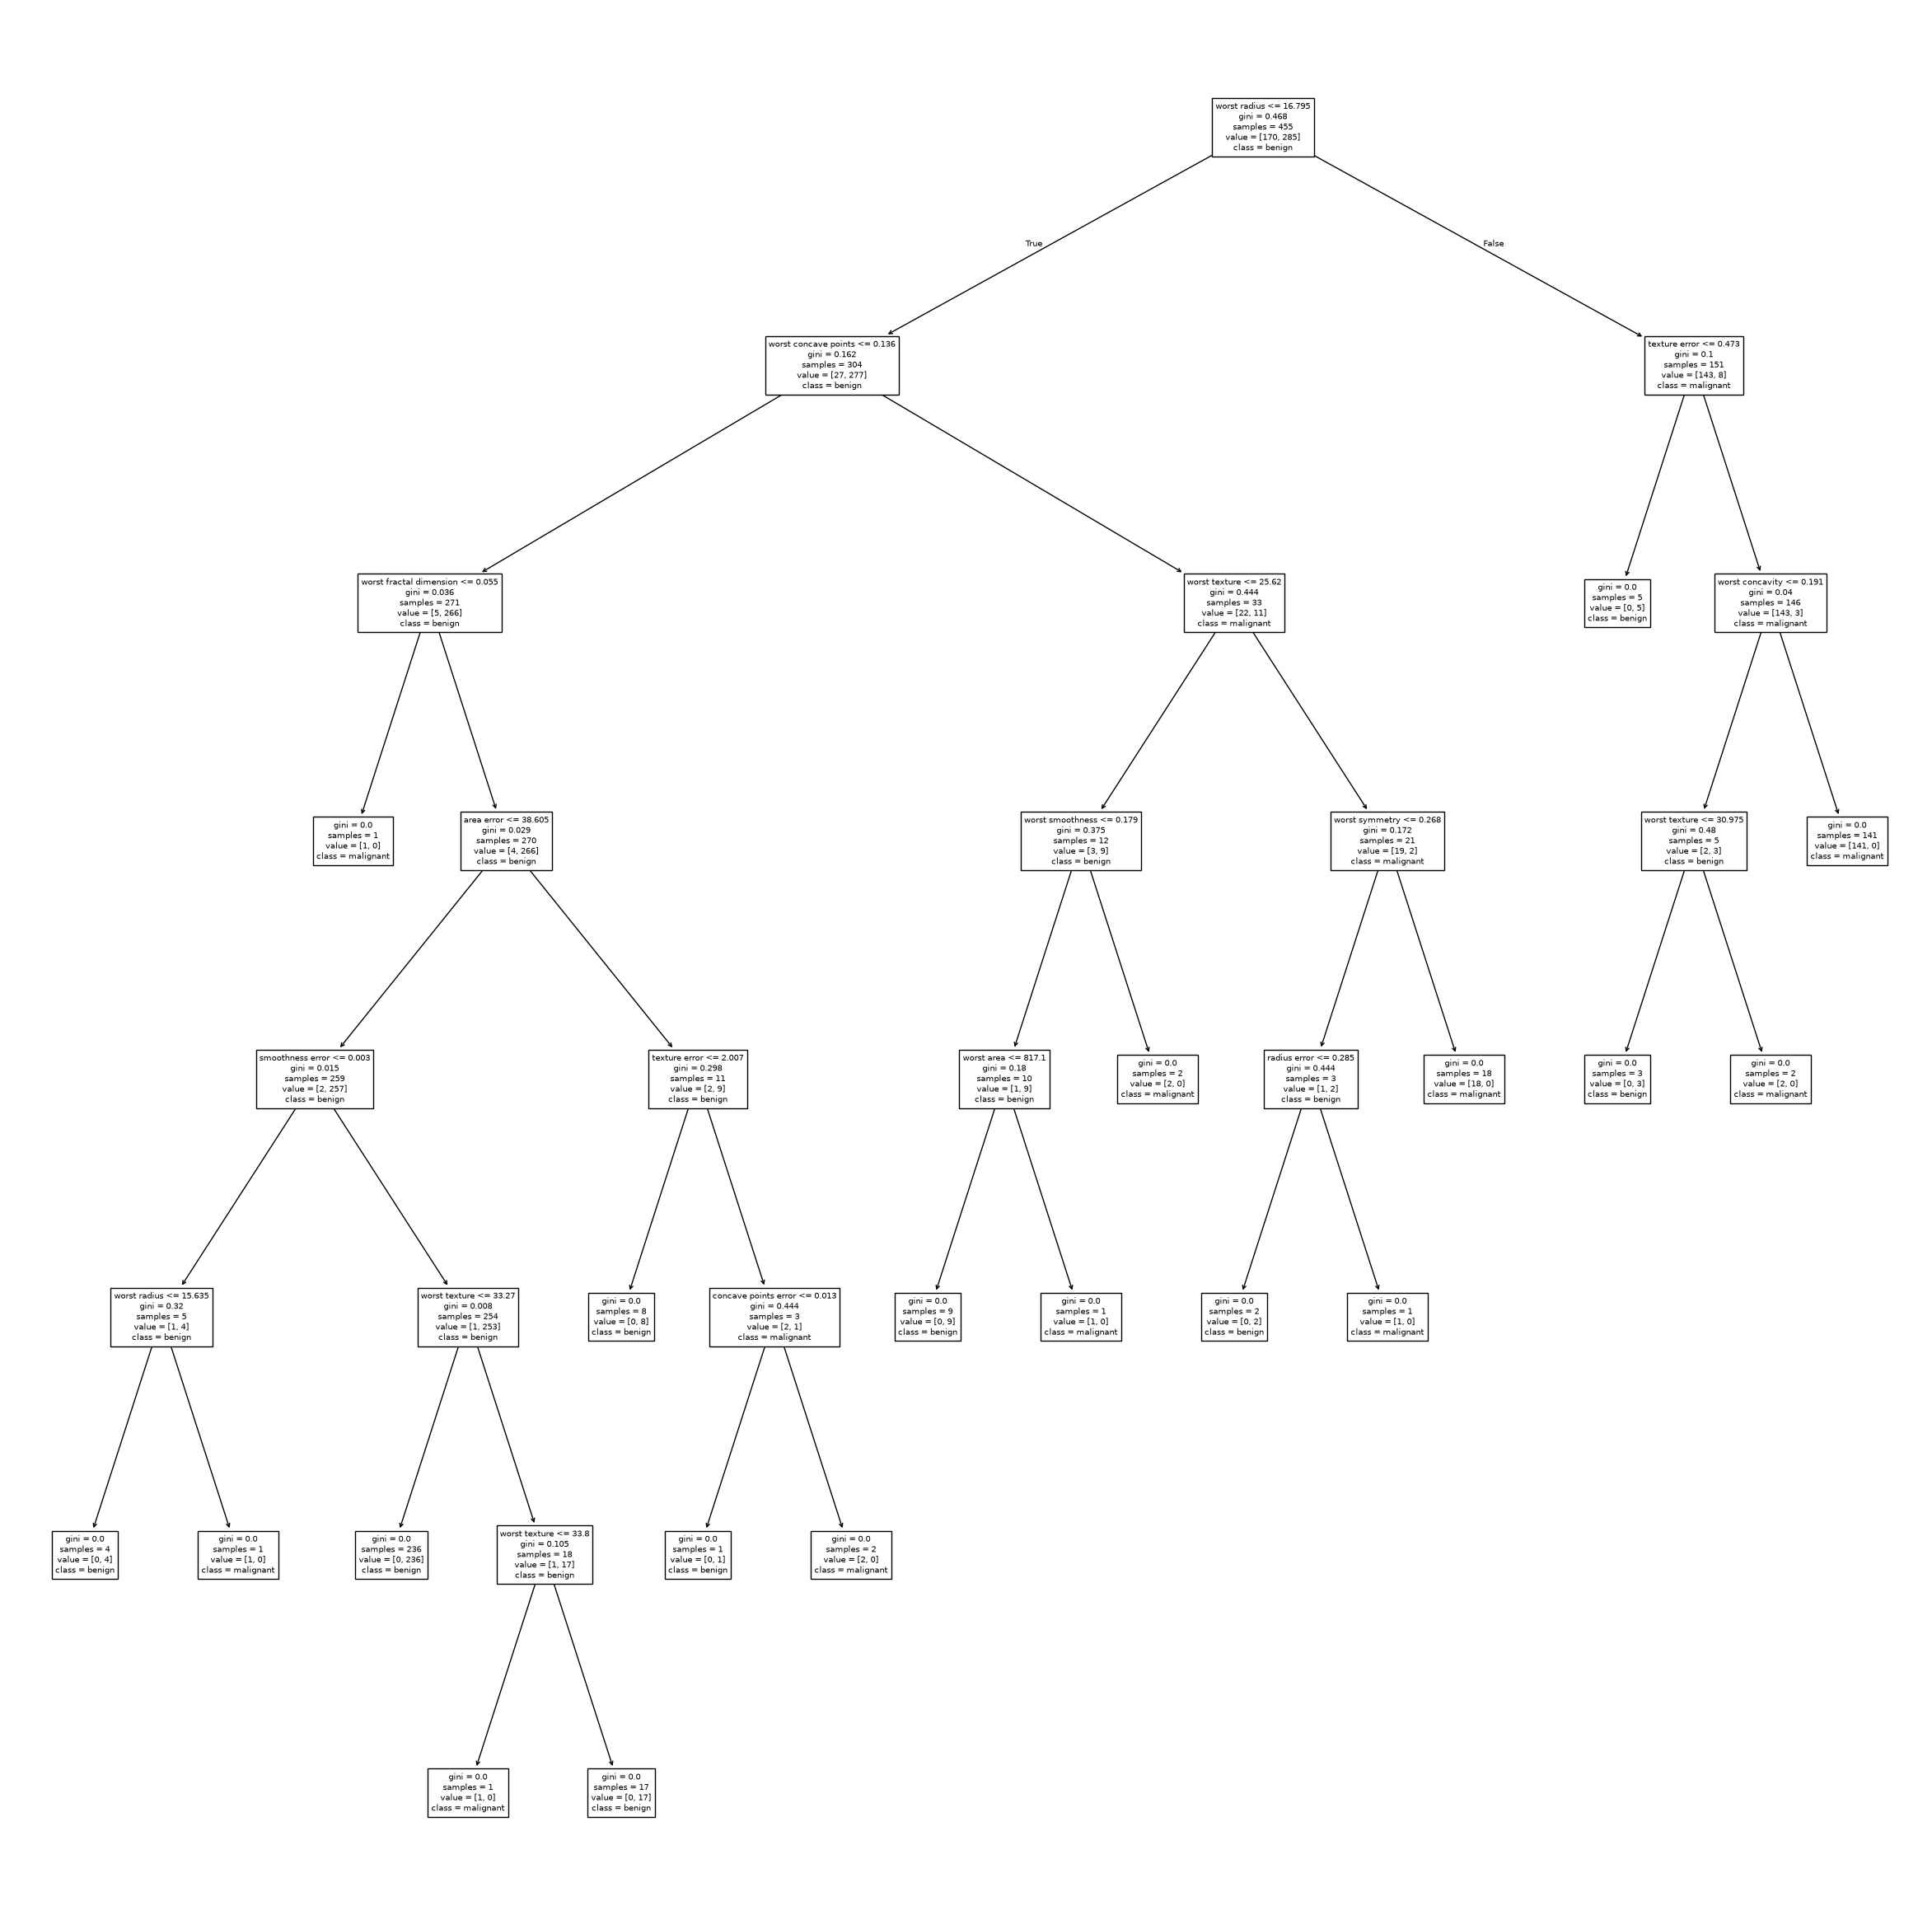

In [28]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 30))
tree_dot = plot_tree(model,
                     feature_names=cancer.feature_names,
                     class_names=cancer.target_names)

In [29]:
from sklearn.metrics import recall_score

pred_train = model.predict(X_train)

recall_score(y_train, pred_train)

1.0

In [30]:
pred_test = model.predict(X_test)

recall_score(y_test, pred_test)

0.8888888888888888